# Tugas Praktikum 6: Clustering (Advance)

**Nama:** Hilal Tsabitul Azmi Arba'i
**NRP:** 5054251008

Notebook ini menerapkan empat algoritma clustering lanjutan, yaitu Agglomerative Clustering, DBSCAN, Gaussian Mixture Models (GMM), dan Spectral Clustering, pada dataset Palmer Penguins. Hasilnya dievaluasi dengan Silhouette Score, Rand Index, NMI, dan uji kestabilan.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import dendrogram, linkage, set_link_color_palette
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, rand_score,
                             adjusted_rand_score, normalized_mutual_info_score)

WARNA = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
WARNA_NOISE = '#b5b4ae'
RANDOM_STATE = 42

## 1. Import Dataset

Dataset dibaca langsung dari URL yang diberikan pada soal.

In [2]:
url = 'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv'
df = pd.read_csv(url)
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [3]:
df.shape

(344, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


Dataset terdiri atas 344 baris dan 8 kolom. Terdapat empat kolom numerik hasil pengukuran fisik (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`), tiga kolom kategorikal (`species`, `island`, `sex`), dan kolom `year`. Empat kolom numerik dipakai sebagai fitur clustering, sedangkan `species` hanya dipakai sebagai label pembanding saat evaluasi eksternal.

## 2. Eksplorasi dan Pembersihan Data

In [5]:
df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Kolom fitur masing-masing memiliki 2 nilai kosong, dan kolom `sex` memiliki 11 nilai kosong. Kolom `sex` tidak dipakai sebagai fitur, sehingga baris dengan `sex` kosong tetap dipertahankan. Pembersihan hanya dilakukan pada empat kolom fitur dan kolom `species`.

In [6]:
fitur = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

df_bersih = df.dropna(subset=fitur + ['species']).reset_index(drop=True)

print('Jumlah baris sebelum pembersihan:', len(df))
print('Jumlah baris sesudah pembersihan:', len(df_bersih))
print('Baris yang dihapus:', len(df) - len(df_bersih))

Jumlah baris sebelum pembersihan: 344
Jumlah baris sesudah pembersihan: 342
Baris yang dihapus: 2


In [7]:
df_bersih[fitur].describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


Skala antarkolom sangat berbeda. Rata-rata `body_mass_g` sekitar 4.202 gram dengan simpangan baku 802, sedangkan `bill_depth_mm` rata-ratanya hanya 17,15 mm dengan simpangan baku 1,97. Tanpa standardisasi, jarak antartitik hampir seluruhnya ditentukan oleh massa tubuh, sehingga ketiga fitur lainnya nyaris tidak berpengaruh.

In [8]:
jumlah_spesies = pd.DataFrame({
    'Sebelum': df['species'].value_counts(),
    'Sesudah': df_bersih['species'].value_counts(),
})
jumlah_spesies

,Sebelum,Sesudah
species,,
Adelie,152,151
Gentoo,124,123
Chinstrap,68,68


Dua baris yang dihapus berasal dari spesies Adelie dan Gentoo, masing-masing satu baris. Distribusi spesies tidak seimbang: Adelie 151 ekor, Gentoo 123 ekor, dan Chinstrap 68 ekor.

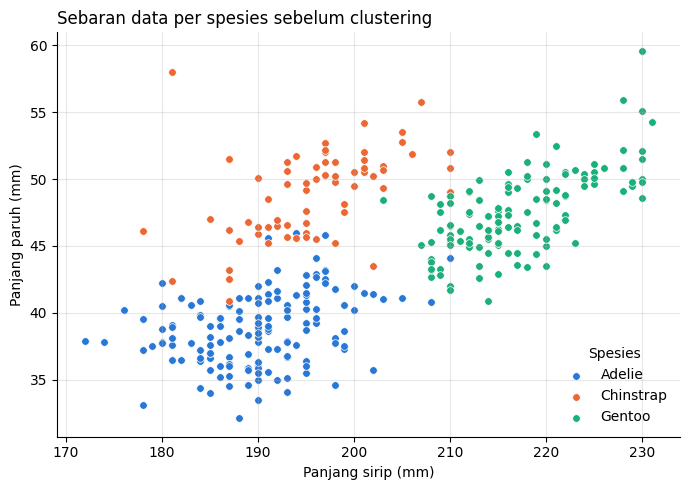

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for i, spesies in enumerate(['Adelie', 'Chinstrap', 'Gentoo']):
    data = df_bersih[df_bersih['species'] == spesies]
    ax.scatter(data['flipper_length_mm'], data['bill_length_mm'], s=30,
               color=WARNA[i], edgecolor='white', linewidth=0.5, label=spesies)
ax.set_xlabel('Panjang sirip (mm)')
ax.set_ylabel('Panjang paruh (mm)')
ax.set_title('Sebaran data per spesies sebelum clustering', loc='left')
ax.legend(title='Spesies', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Pada scatter plot awal, Gentoo terlihat terpisah dengan sirip yang lebih panjang. Adelie dan Chinstrap memiliki panjang sirip yang mirip dan terutama dibedakan oleh panjang paruh, sehingga batas keduanya lebih berdekatan. Perbedaan inilah yang nantinya menjadi tantangan bagi algoritma clustering.

## 3. Standardisasi Data

Fitur distandardisasi dengan z-score agar setiap kolom memiliki rata-rata 0 dan simpangan baku 1. Seluruh algoritma dijalankan pada data hasil standardisasi ini.

In [10]:
X = df_bersih[fitur]
y = df_bersih['species']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=fitur).describe().round(3)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000,342.000,342.000,342.000
mean,0.000,0.000,-0.000,0.000
std,1.001,1.001,1.001,1.001
min,-2.169,-2.054,-2.059,-1.875
25%,-0.862,-0.787,-0.777,-0.814
50%,0.097,0.075,-0.279,-0.190
75%,0.840,0.785,0.861,0.685
max,2.876,2.205,2.143,2.620


## 4. Penerapan Algoritma

### 4.1 Agglomerative Clustering

Linkage yang dipakai adalah **ward**, yaitu menggabungkan dua kluster yang menghasilkan kenaikan jumlah kuadrat jarak dalam kluster (within-cluster variance) paling kecil. Ward cenderung menghasilkan kluster yang kompak dan berukuran seimbang.

In [11]:
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
label_agg = agg.fit_predict(X_scaled)

pd.crosstab(y, label_agg, rownames=['Spesies'], colnames=['Kluster Agglomerative'])

Kluster Agglomerative,0,1,2
Spesies,,,
Adelie,151,0,0
Chinstrap,11,0,57
Gentoo,0,123,0


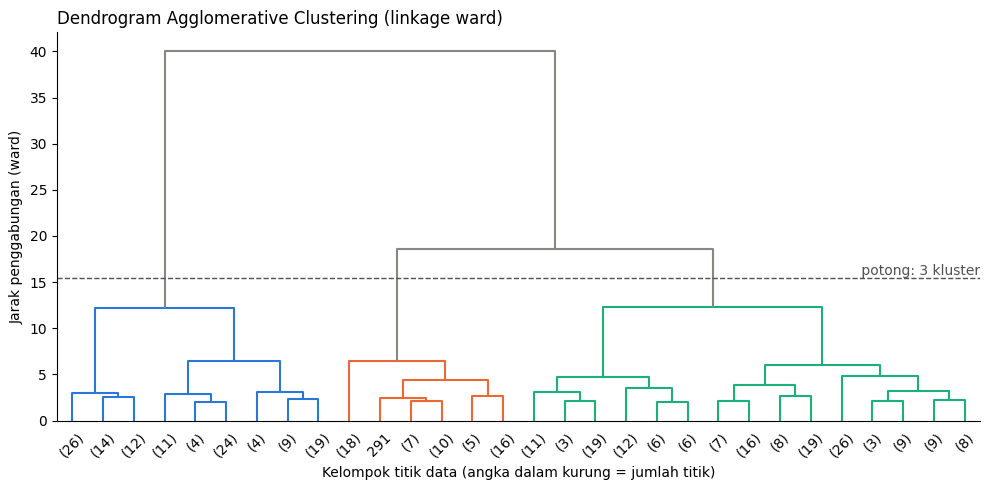

In [12]:
Z = linkage(X_scaled, method='ward')
batas_potong = (Z[-3, 2] + Z[-2, 2]) / 2  # tinggi potong yang menghasilkan 3 kluster

set_link_color_palette(WARNA[:3])
fig, ax = plt.subplots(figsize=(10, 5))
dendrogram(Z, truncate_mode='lastp', p=30, color_threshold=batas_potong,
           above_threshold_color='#898781', ax=ax)
ax.axhline(batas_potong, color='#52514e', linestyle='--', linewidth=1)
ax.text(ax.get_xlim()[1], batas_potong, ' potong: 3 kluster', va='bottom', ha='right', color='#52514e')
ax.set_title('Dendrogram Agglomerative Clustering (linkage ward)', loc='left')
ax.set_xlabel('Kelompok titik data (angka dalam kurung = jumlah titik)')
ax.set_ylabel('Jarak penggabungan (ward)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
set_link_color_palette(None)

Dendrogram dipotong pada tinggi yang menghasilkan tiga kluster. Jarak penggabungan di atas garis potong jauh lebih besar daripada di bawahnya, yang menunjukkan bahwa tiga kluster tersebut cukup terpisah satu sama lain. Agglomerative memisahkan Gentoo dengan sempurna, tetapi 11 Chinstrap masuk ke kluster Adelie.

### 4.2 DBSCAN

DBSCAN dimulai dengan eps 0,5 dan MinPts 5, lalu dicoba beberapa nilai eps lain untuk melihat pengaruhnya terhadap jumlah kluster dan jumlah titik noise.

In [13]:
hasil_eps = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    label = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    hasil_eps.append({
        'eps': eps,
        'jumlah_kluster': len(set(label) - {-1}),
        'jumlah_noise': int((label == -1).sum()),
    })

tabel_eps = pd.DataFrame(hasil_eps)
tabel_eps

,eps,jumlah_kluster,jumlah_noise
0,0.3,4,317
1,0.4,10,171
2,0.5,4,69
3,0.6,2,33
4,0.7,2,16
5,0.8,2,5
6,0.9,2,2
7,1.0,2,1


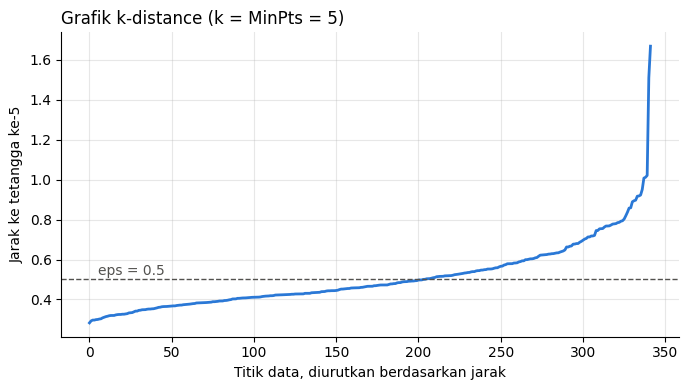

In [14]:
jarak, _ = NearestNeighbors(n_neighbors=5).fit(X_scaled).kneighbors(X_scaled)
jarak_k = np.sort(jarak[:, -1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(jarak_k, color=WARNA[0], linewidth=2)
ax.axhline(0.5, color='#52514e', linestyle='--', linewidth=1)
ax.text(5, 0.52, 'eps = 0.5', color='#52514e')
ax.set_xlabel('Titik data, diurutkan berdasarkan jarak')
ax.set_ylabel('Jarak ke tetangga ke-5')
ax.set_title('Grafik k-distance (k = MinPts = 5)', loc='left')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Tidak ada nilai eps yang menghasilkan tepat tiga kluster:

- **eps 0,3 dan 0,4:** terlalu kecil, sehingga sebagian besar titik dianggap noise (317 dan 171 titik).
- **eps 0,5:** menghasilkan 4 kluster dengan 69 titik noise.
- **eps 0,6 ke atas:** hanya menghasilkan 2 kluster, karena Adelie dan Chinstrap selalu tergabung.

Grafik k-distance menunjukkan bahwa eps 0,5 berada di bagian tengah kurva, sehingga sebagian titik di daerah yang lebih renggang menjadi noise. Model akhir memakai **eps 0,5**, karena hanya nilai ini yang masih memisahkan Chinstrap dari Adelie, walaupun disertai noise.

In [15]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
label_db = dbscan.fit_predict(X_scaled)

print('Jumlah kluster:', len(set(label_db) - {-1}))
print('Jumlah titik noise:', (label_db == -1).sum())
pd.crosstab(y, label_db, rownames=['Spesies'], colnames=['Kluster DBSCAN (-1 = noise)'])

Jumlah kluster: 4
Jumlah titik noise: 69


Kluster DBSCAN (-1 = noise),-1,0,1,2,3
Spesies,,,,,
Adelie,36,115,0,0,0
Chinstrap,23,3,0,15,27
Gentoo,10,0,113,0,0


Pada eps 0,5, Adelie dan Gentoo masing-masing membentuk satu kluster, tetapi Chinstrap terpecah menjadi dua kluster kecil (15 dan 27 ekor), dan 23 ekor lainnya menjadi noise. Hal ini terjadi karena DBSCAN mengelompokkan berdasarkan kepadatan, sedangkan Adelie dan Chinstrap bersinggungan pada daerah dengan kepadatan yang mirip, sehingga tidak ada nilai eps yang dapat memisahkan keduanya dengan bersih.

### 4.3 Gaussian Mixture Models (GMM)

GMM memodelkan data sebagai campuran tiga distribusi Gaussian dengan matriks kovarians penuh, sehingga setiap kluster boleh berbentuk elips dengan arah dan ukuran berbeda.

In [16]:
gmm = GaussianMixture(n_components=3, random_state=RANDOM_STATE)
label_gmm = gmm.fit_predict(X_scaled)

pd.crosstab(y, label_gmm, rownames=['Spesies'], colnames=['Komponen GMM'])

Komponen GMM,0,1,2
Spesies,,,
Adelie,2,0,149
Chinstrap,65,0,3
Gentoo,0,123,0


GMM memberikan pemisahan paling mendekati spesies asli. Gentoo terpisah sempurna, dan hanya 5 titik yang tertukar antara Adelie dan Chinstrap (2 Adelie dan 3 Chinstrap).

### 4.4 Spectral Clustering

Spectral Clustering membangun graf kemiripan antartitik dengan `affinity='nearest_neighbors'`, lalu mengelompokkan titik berdasarkan struktur graf tersebut.

In [17]:
spectral = SpectralClustering(n_clusters=3, affinity='nearest_neighbors',
                              random_state=RANDOM_STATE)
label_spectral = spectral.fit_predict(X_scaled)

pd.crosstab(y, label_spectral, rownames=['Spesies'], colnames=['Kluster Spectral'])

/home/hilal/kuliah/DM/Modul-DM-RKA/.venv/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Kluster Spectral,0,1,2
Spesies,,,
Adelie,151,0,0
Chinstrap,11,0,57
Gentoo,0,123,0


In [18]:
from scipy.sparse.csgraph import connected_components

n_komponen, komponen = connected_components(spectral.affinity_matrix_)
print('Jumlah komponen terhubung pada graf tetangga:', n_komponen)
pd.crosstab(y, komponen, rownames=['Spesies'], colnames=['Komponen graf'])

Jumlah komponen terhubung pada graf tetangga: 2


Komponen graf,0,1
Spesies,,
Adelie,151,0
Chinstrap,68,0
Gentoo,0,123


Saat dijalankan, Spectral Clustering memberi peringatan bahwa graf tetangganya tidak terhubung penuh. Pemeriksaan komponen graf menunjukkan bahwa graf terbelah tepat menjadi dua bagian: seluruh Gentoo di satu komponen, sedangkan Adelie dan Chinstrap di komponen lain. Artinya, peringatan ini muncul karena Gentoo memang terpisah jauh dari dua spesies lainnya, bukan karena kesalahan. Nilai `n_neighbors` tidak disesuaikan, karena menyetelnya berdasarkan kecocokan dengan spesies berarti memakai label saat clustering.

Hasil Spectral Clustering hampir identik dengan Agglomerative: Gentoo terpisah sempurna, dan 11 Chinstrap masuk ke kluster Adelie. Jumlah per spesiesnya sama, tetapi keduanya berbeda pada 2 titik di perbatasan Adelie dan Chinstrap (ARI antara keduanya 0,984).

### 4.5 Visualisasi Hasil Clustering

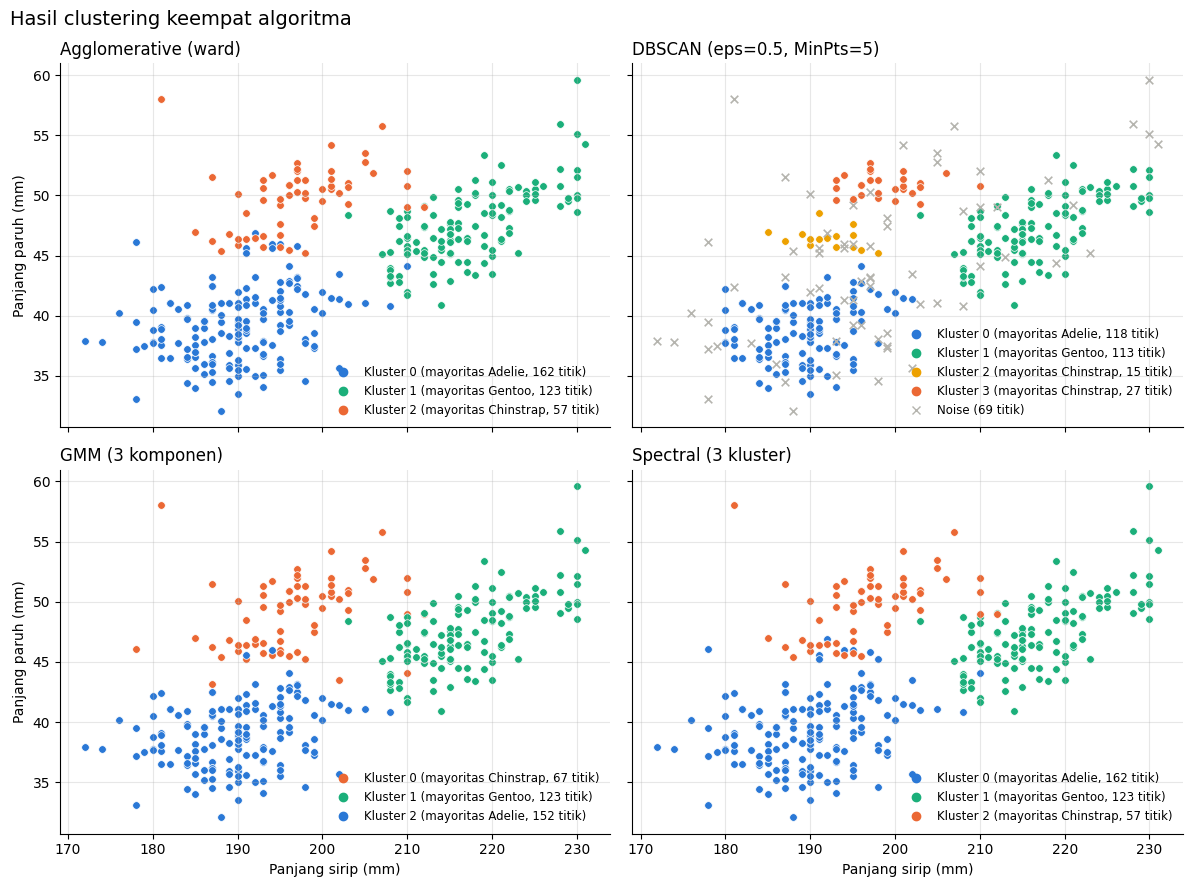

In [19]:
SPESIES = ['Adelie', 'Chinstrap', 'Gentoo']

def warna_kluster(label):
    # Warna kluster mengikuti spesies mayoritasnya (hanya untuk tampilan, setelah clustering selesai)
    peta, terpakai = {}, set()
    for k in sorted(set(label) - {-1}, key=lambda k: -(label == k).sum()):
        mayoritas = y[label == k].mode()[0]
        warna = WARNA[SPESIES.index(mayoritas)]
        if warna in terpakai:
            warna = next(w for w in WARNA if w not in terpakai)
        peta[k] = (warna, mayoritas)
        terpakai.add(warna)
    return peta

hasil_label = {
    'Agglomerative (ward)': label_agg,
    'DBSCAN (eps=0.5, MinPts=5)': label_db,
    'GMM (3 komponen)': label_gmm,
    'Spectral (3 kluster)': label_spectral,
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, (nama, label) in zip(axes.ravel(), hasil_label.items()):
    handles = []
    for k, (warna, mayoritas) in sorted(warna_kluster(label).items()):
        m = label == k
        ax.scatter(X['flipper_length_mm'][m], X['bill_length_mm'][m], s=30,
                   color=warna, edgecolor='white', linewidth=0.5)
        handles.append(Line2D([], [], marker='o', linestyle='', color=warna,
                              label=f'Kluster {k} (mayoritas {mayoritas}, {m.sum()} titik)'))
    if (label == -1).any():
        m = label == -1
        ax.scatter(X['flipper_length_mm'][m], X['bill_length_mm'][m], s=30,
                   color=WARNA_NOISE, marker='x', linewidth=1.2)
        handles.append(Line2D([], [], marker='x', linestyle='', color=WARNA_NOISE,
                              label=f'Noise ({m.sum()} titik)'))
    ax.set_title(nama, loc='left')
    ax.legend(handles=handles, frameon=False, fontsize=8.5, loc='lower right')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel('Panjang sirip (mm)')
for ax in axes[:, 0]:
    ax.set_ylabel('Panjang paruh (mm)')
fig.suptitle('Hasil clustering keempat algoritma', x=0.01, ha='left', fontsize=14)
plt.tight_layout()
plt.show()

Scatter plot memakai fitur asli (panjang sirip dan panjang paruh) agar mudah dibandingkan dengan sebaran awal, walaupun clustering dijalankan pada keempat fitur yang sudah distandardisasi. Nomor kluster bersifat arbitrer, sehingga warna setiap kluster disamakan dengan warna spesies mayoritasnya pada scatter plot awal agar keempat panel mudah dibandingkan. Label spesies hanya dipakai untuk pewarnaan setelah clustering selesai, tidak untuk proses clustering. Pada DBSCAN, kluster Chinstrap kedua diberi warna kuning karena warna Chinstrap sudah dipakai kluster Chinstrap yang lebih besar.

## 5. Evaluasi Hasil Clustering

### 5.1 Silhouette Score, Rand Index, dan NMI

Silhouette Score mengukur seberapa kompak dan terpisah kluster tanpa memakai label (evaluasi internal). Rand Index dan NMI membandingkan hasil clustering dengan kolom `species` (evaluasi eksternal). Untuk DBSCAN, Silhouette dihitung tanpa titik noise.

In [20]:
def evaluasi(nama, label):
    bukan_noise = label != -1
    return {
        'Algoritma': nama,
        'Jumlah kluster': len(set(label[bukan_noise])),
        'Noise dibuang': int((~bukan_noise).sum()),
        'Silhouette': silhouette_score(X_scaled[bukan_noise], label[bukan_noise]),
        'Rand Index': rand_score(y, label),
        'NMI': normalized_mutual_info_score(y, label),
    }

tabel_evaluasi = pd.DataFrame([evaluasi(n, l) for n, l in hasil_label.items()]).set_index('Algoritma')
tabel_evaluasi.round(3)

,Jumlah kluster,Noise dibuang,Silhouette,Rand Index,NMI
Algoritma,,,,,
Agglomerative (ward),3,0,0.454,0.961,0.901
"DBSCAN (eps=0.5, MinPts=5)",4,69,0.424,0.853,0.663
GMM (3 komponen),3,0,0.455,0.982,0.935
Spectral (3 kluster),3,0,0.455,0.961,0.901


### 5.2 Uji Kestabilan

Setiap algoritma dijalankan ulang pada 90% data yang diambil acak, sebanyak tiga kali dengan seed berbeda, memakai parameter yang sama dengan model pada data penuh. Kestabilan diukur dengan Adjusted Rand Index (ARI) antara label pada subset dan label model data penuh untuk titik yang sama. ARI bernilai 1 jika pengelompokannya identik, dan sekitar 0 jika kecocokannya setara dengan acak. Untuk DBSCAN, noise diperlakukan sebagai satu label tersendiri.

In [21]:
def jalankan(nama, data):
    if nama.startswith('Agglomerative'):
        return AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(data)
    if nama.startswith('DBSCAN'):
        return DBSCAN(eps=0.5, min_samples=5).fit_predict(data)
    if nama.startswith('GMM'):
        return GaussianMixture(n_components=3, random_state=RANDOM_STATE).fit_predict(data)
    return SpectralClustering(n_clusters=3, affinity='nearest_neighbors',
                              random_state=RANDOM_STATE).fit_predict(data)

import warnings

n = len(X_scaled)
hasil_stabil = []
warnings.filterwarnings('ignore', message='Graph is not fully connected')  # sudah dijelaskan di bagian 4.4
for percobaan, seed in enumerate([0, 1, 2], start=1):
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(n, size=int(0.9 * n), replace=False))
    for nama, label_penuh in hasil_label.items():
        label_sub = jalankan(nama, X_scaled[idx])
        hasil_stabil.append({
            'Algoritma': nama,
            'Percobaan': percobaan,
            'ARI vs data penuh': adjusted_rand_score(label_penuh[idx], label_sub),
            'NMI vs spesies': normalized_mutual_info_score(y.iloc[idx], label_sub),
        })

tabel_stabil = pd.DataFrame(hasil_stabil)
tabel_stabil.pivot(index='Algoritma', columns='Percobaan', values='ARI vs data penuh').round(3)

Percobaan,1,2,3
Algoritma,,,
Agglomerative (ward),0.940,0.991,0.957
"DBSCAN (eps=0.5, MinPts=5)",0.798,0.945,0.947
GMM (3 komponen),1.000,0.983,0.873
Spectral (3 kluster),0.965,0.883,1.000


### 5.3 Tabel Perbandingan

In [22]:
ringkas_stabil = tabel_stabil.groupby('Algoritma').agg(
    **{'Stabilitas (rata-rata ARI)': ('ARI vs data penuh', 'mean'),
       'Stabilitas (std ARI)': ('ARI vs data penuh', 'std'),
       'NMI pada subset (rata-rata)': ('NMI vs spesies', 'mean')})

tabel_perbandingan = tabel_evaluasi.join(ringkas_stabil)
tabel_perbandingan.round(3)

,Jumlah kluster,Noise dibuang,Silhouette,Rand Index,NMI,Stabilitas (rata-rata ARI),Stabilitas (std ARI),NMI pada subset (rata-rata)
Algoritma,,,,,,,,
Agglomerative (ward),3,0,0.454,0.961,0.901,0.963,0.026,0.921
"DBSCAN (eps=0.5, MinPts=5)",4,69,0.424,0.853,0.663,0.896,0.086,0.641
GMM (3 komponen),3,0,0.455,0.982,0.935,0.952,0.069,0.898
Spectral (3 kluster),3,0,0.455,0.961,0.901,0.949,0.060,0.884


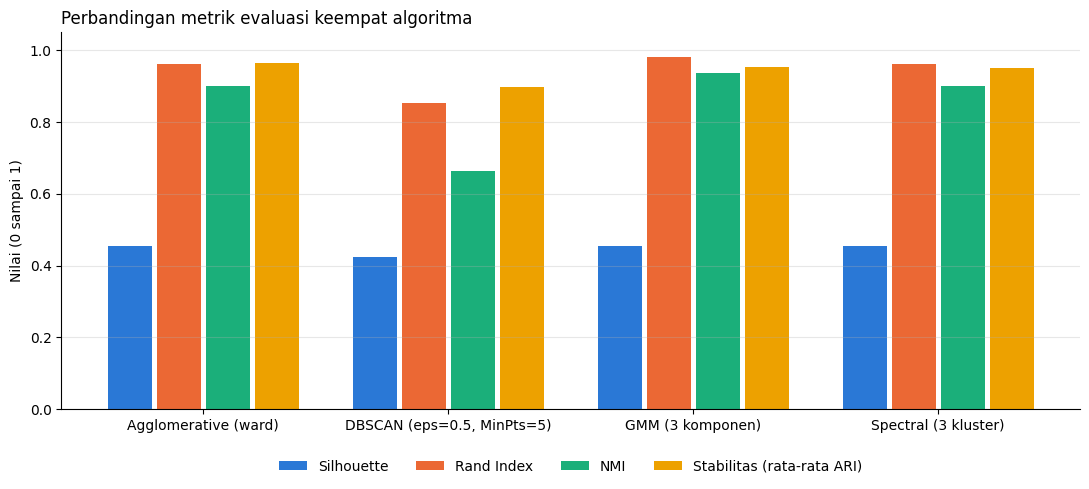

In [23]:
metrik = ['Silhouette', 'Rand Index', 'NMI', 'Stabilitas (rata-rata ARI)']
nama_algo = tabel_perbandingan.index
x = np.arange(len(nama_algo))
lebar = 0.2

fig, ax = plt.subplots(figsize=(11, 5))
for i, m in enumerate(metrik):
    ax.bar(x + (i - 1.5) * lebar, tabel_perbandingan[m], width=lebar * 0.9,
           color=WARNA[i], label=m)
ax.set_xticks(x)
ax.set_xticklabels(nama_algo)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Nilai (0 sampai 1)')
ax.set_title('Perbandingan metrik evaluasi keempat algoritma', loc='left')
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.1))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 5.4 Analisis Evaluasi

**Silhouette Score.** Agglomerative, GMM, dan Spectral memiliki Silhouette yang hampir sama, yaitu 0,454 sampai 0,455. Nilai ini tergolong sedang, karena Adelie dan Chinstrap bersinggungan sehingga kluster tidak terpisah sempurna. DBSCAN memperoleh 0,424 setelah membuang 69 titik noise (20,2% data). Karena ketiga algoritma terbaik nyaris seri, Silhouette saja tidak cukup untuk memilih algoritma terbaik.

**Rand Index dan NMI.** GMM paling sesuai dengan spesies asli, dengan Rand Index 0,982 dan NMI 0,935. Agglomerative dan Spectral sama-sama memperoleh Rand Index 0,961 dan NMI 0,901, karena keduanya salah menempatkan 11 Chinstrap ke kluster Adelie. DBSCAN paling rendah, dengan Rand Index 0,853 dan NMI 0,663, karena Chinstrap terpecah menjadi dua kluster dan banyak titik dianggap noise.

**Kestabilan.** Agglomerative paling stabil, dengan rata-rata ARI 0,963 dan simpangan baku terkecil (0,026), karena prosesnya deterministik dan tidak bergantung pada inisialisasi acak. GMM (0,952) dan Spectral (0,949) juga stabil, tetapi masing-masing pernah turun pada satu percobaan, yaitu 0,873 untuk GMM dan 0,883 untuk Spectral. Penurunan ini menunjukkan bahwa titik-titik di perbatasan Adelie dan Chinstrap mudah berpindah kluster saat sebagian data dihapus. DBSCAN paling tidak stabil (rata-rata 0,896, terendah 0,798), karena menghapus 10% data mengubah kepadatan lokal, sehingga titik bisa berpindah antara kluster dan noise dengan eps yang sama.

## 6. Laporan

### 6.1 Hasil Eksplorasi dan Pembersihan Data

Dataset Palmer Penguins berisi 344 baris. Dua baris dihapus karena keempat fitur numeriknya kosong, sehingga tersisa 342 baris: Adelie 151, Gentoo 123, dan Chinstrap 68. Nilai kosong pada kolom `sex` dibiarkan karena kolom tersebut tidak dipakai. Skala fitur sangat berbeda, dari belasan milimeter sampai ribuan gram, sehingga data distandardisasi dengan z-score sebelum clustering. Scatter plot awal menunjukkan Gentoo terpisah jelas, sedangkan Adelie dan Chinstrap berdekatan dan terutama dibedakan oleh panjang paruh.

### 6.2 Ringkasan Evaluasi

| Algoritma | Kluster | Noise | Silhouette | Rand Index | NMI | Stabilitas (ARI) |
|---|---:|---:|---:|---:|---:|---:|
| Agglomerative (ward) | 3 | 0 | 0,454 | 0,961 | 0,901 | **0,963** |
| DBSCAN (eps 0,5) | 4 | 69 | 0,424 | 0,853 | 0,663 | 0,896 |
| GMM (3 komponen) | 3 | 0 | **0,455** | **0,982** | **0,935** | 0,952 |
| Spectral (3 kluster) | 3 | 0 | **0,455** | 0,961 | 0,901 | 0,949 |

Semua algoritma memisahkan Gentoo dengan sempurna. Perbedaan kinerja hampir seluruhnya ditentukan oleh kemampuan memisahkan Adelie dan Chinstrap.

### 6.3 Kesimpulan

**Gaussian Mixture Models (GMM) adalah algoritma yang paling cocok untuk dataset ini.** Alasannya:

1. **Paling sesuai dengan spesies asli.** GMM memperoleh Rand Index (0,982) dan NMI (0,935) tertinggi, dan hanya salah menempatkan 5 dari 342 penguin.
2. **Bentuk modelnya sesuai dengan data.** GMM dengan kovarians penuh memodelkan setiap kluster sebagai elips yang boleh memanjang dan miring. Ukuran tubuh penguin dalam satu spesies saling berkorelasi, misalnya penguin bersirip panjang cenderung lebih berat, sehingga sebaran tiap spesies memang berbentuk elips. Ward cenderung membentuk kluster bulat dan seimbang, sehingga Chinstrap yang jumlahnya lebih sedikit sebagian terserap ke Adelie.
3. **Kualitas internal dan kestabilannya tetap tinggi.** Silhouette GMM termasuk tertinggi (0,455), dan rata-rata kestabilannya 0,952, hanya sedikit di bawah Agglomerative.

Agglomerative Clustering menjadi alternatif terbaik jika kestabilan lebih diutamakan, karena hasilnya paling konsisten (ARI 0,963) dan dendrogramnya mudah ditafsirkan. Spectral Clustering memberikan hasil yang hampir identik dengan Agglomerative. DBSCAN paling tidak cocok, karena tidak ada nilai eps yang menghasilkan tiga kluster: Adelie dan Chinstrap bersinggungan dengan kepadatan yang mirip, sehingga DBSCAN hanya bisa memecah Chinstrap atau menggabungkannya dengan Adelie.

Perlu dicatat bahwa pemilihan ini memakai label spesies yang dalam kasus nyata biasanya tidak tersedia. Tanpa label, Silhouette ketiga algoritma terbaik nyaris seri, sehingga keputusan akan lebih bergantung pada kestabilan dan kesesuaian bentuk kluster dengan pengetahuan tentang data.